# UE Data Mining - Projet

Notebook à compléter dans le cadre du projet de l’UE Data Mining des Master 2 Intelligence Artificielle et Master 2 Data Science de l’année scolaire 2026-2027.

* Nom du groupe :
* Membres du groupe :
    * Prénom NOM


## Pensez à mettre des titres

Et du texte pour expliquer les différentes étapes de votre raisonnement, les résultats obtenus et les conclusions que vous en avez tiré.

Pour rappel, ce notebook sera aussi votre rapport sur ce projet, donc soyez précis et rigoureux dans ce que vous décrivez et écrivez.

In [32]:
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CHARGEMENT DES DONNÉES
# ==============================================================================
df = pd.read_csv("data/ecology/bat_surveys.csv")

In [33]:
# ==============================================================================
# 2. NETTOYAGE DES REDONDANCES ET COLONNES INUTILES
# ==============================================================================
# Suppression des doublons de lignes
df = df.drop_duplicates()

# Suppression des colonnes inutiles ou redondantes
cols_to_drop = ["survey_start", "survey_end", "survey_id"]
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

In [34]:
# ==============================================================================
# 3. HARMONISATION ET HARMONISATION TEXTUELLE
# ==============================================================================
# Nettoyage des chaînes textuelles
if "survey_method" in df.columns:
    df["survey_method"] = df["survey_method"].str.lower()

# A. Nettoyage des colonnes décimales (remplacement de la virgule par le point)
cols_float = ["observation_hours", "weather_interference", "colony_estimate"]
for col in cols_float:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", ".", regex=False)
            .replace("nan", np.nan)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

# B. Nettoyage des suffixes parasites (" count")
cols_count = [
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count",
]
for col in cols_count:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str).str.replace(" count", "", regex=False).str.strip(),
            errors="coerce",
        )

In [35]:
# ==============================================================================
# 4. ENCODAGE ET TRAITEMENT DES VALEURS MANQUANTES
# ==============================================================================
# Encodage ordinal de la qualité d'observation
mapping_labels = {"high": 1, "acceptable": 2, "limited": 3}
if "survey_quality" in df.columns:
    df["survey_quality"] = df["survey_quality"].replace(mapping_labels)

/tmp/ipykernel_20580/870851701.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["survey_quality"] = df["survey_quality"].replace(mapping_labels)


In [36]:
# ==============================================================================
# 4. TRAITEMENT DES OUTLIERS (CONVERSION EN NaN - CONSIGNE PROF)
# ==============================================================================
# Méthode de l'IQR (Écart Interquartile) pour repérer et annuler les outliers
cols_outliers = ["weather_interference", "colony_estimate"]
for col in cols_outliers:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        borne_sup = q3 + 1.5 * iqr

        # Remplacement des valeurs supérieures à la borne par NaN
        df.loc[df[col] > borne_sup, col] = np.nan

In [37]:
# ==============================================================================
# 5. IMPUTATION DES VALEURS MANQUANTES (INFÉRENCE - CONSIGNE PROF)
# ==============================================================================
# A. Inférer les variables numériques (outliers convertis inclus) par la MÉDIANE
for col in cols_float:
    if col in df.columns and df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# B. Inférer les variables catégorielles par le MODE (valeur la plus fréquente)
if "observer_team" in df.columns and df["observer_team"].isnull().sum() > 0:
    mode_team = df["observer_team"].mode()[0]
    df["observer_team"] = df["observer_team"].fillna(mode_team)

In [38]:
# ==============================================================================
# 6. SAUVEGARDE ET RECHARGEMENT
# ==============================================================================
output_file = "cleaned_bat_survey.csv"
df.to_csv(output_file, index=False)
df = pd.read_csv(output_file)

In [39]:
# ==============================================================================
# 7. RAPPORT ET RÉSULTAT DU NETTOYAGE
# ==============================================================================
print("=" * 50)
print("1. TYPES ET STRUCTURE")
print("=" * 50)
df.info()

print("\n" + "=" * 50)
print("2. VÉRIFICATION DES VALEURS MANQUANTES")
print("=" * 50)
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "✅ Aucune valeur manquante !")

print("\n" + "=" * 50)
print("3. TEST DE PRÉSENCE DU MOT PARASITE 'count'")
print("=" * 50)
parasite_found = False
for col in df.select_dtypes(include=["object"]).columns:
    count_matches = df[col].astype(str).str.contains("count", case=False).sum()
    if count_matches > 0:
        print(f"⚠️ 'count' encore présent dans '{col}' ({count_matches} occurrences)")
        parasite_found = True
if not parasite_found:
    print("✅ Aucun mot 'count' parasite trouvé.")

print("\n" + "=" * 50)
print("4. COMPTAGE ET DISTRIBUTION DES CATÉGORIES TEXTE")
print("=" * 50)
for col in df.select_dtypes(include=["object"]).columns:
    counts = df[col].value_counts(dropna=False)
    formatted = " / ".join([f"{val}: {count}" for val, count in counts.items()])
    print(f"**{col}** -> {formatted}\n")

print("=" * 50)
print("5. RESUMÉ STATISTIQUE DES NUMÉRIQUES")
print("=" * 50)
print(df.describe().T[["min", "mean", "max"]])

1. TYPES ET STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4992 entries, 0 to 4991
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   site_code                 4992 non-null   object 
 1   survey_method             4992 non-null   object 
 2   observation_hours         4992 non-null   float64
 3   observed_bat_count        4992 non-null   int64  
 4   acoustic_detection_count  4992 non-null   int64  
 5   nightly_visit_count       4992 non-null   int64  
 6   colony_estimate           4992 non-null   float64
 7   comparison_species_count  4992 non-null   int64  
 8   observer_team             4992 non-null   object 
 9   survey_quality            4992 non-null   int64  
 10  weather_interference      4992 non-null   float64
dtypes: float64(3), int64(5), object(3)
memory usage: 429.1+ KB

2. VÉRIFICATION DES VALEURS MANQUANTES
✅ Aucune valeur manquante !

3. TEST DE PRÉSENCE DU 

STATISTIQUES COMPLÈTES DES VARIABLES NUMÉRIQUES
                          Moyenne  Écart-type  Min  Q1 (25%)  Médiane  \
observation_hours           30.33        5.50  5.0      26.9     30.6   
observed_bat_count          14.13        8.25  0.0       8.0     13.0   
acoustic_detection_count    20.48       12.13  0.0      12.0     18.0   
nightly_visit_count         10.11        6.06  0.0       6.0      9.0   
colony_estimate             14.82        7.69  0.0       9.3     13.9   
comparison_species_count    10.71        3.45  1.0       8.0     11.0   
survey_quality               1.49        0.55  1.0       1.0      1.0   
weather_interference        37.13       16.05  0.0      25.1     36.6   

                          Q3 (75%)    Max  
observation_hours             34.1   46.9  
observed_bat_count            18.0   73.0  
acoustic_detection_count      26.0  107.0  
nightly_visit_count           13.0   54.0  
colony_estimate               19.5   37.3  
comparison_species_count      

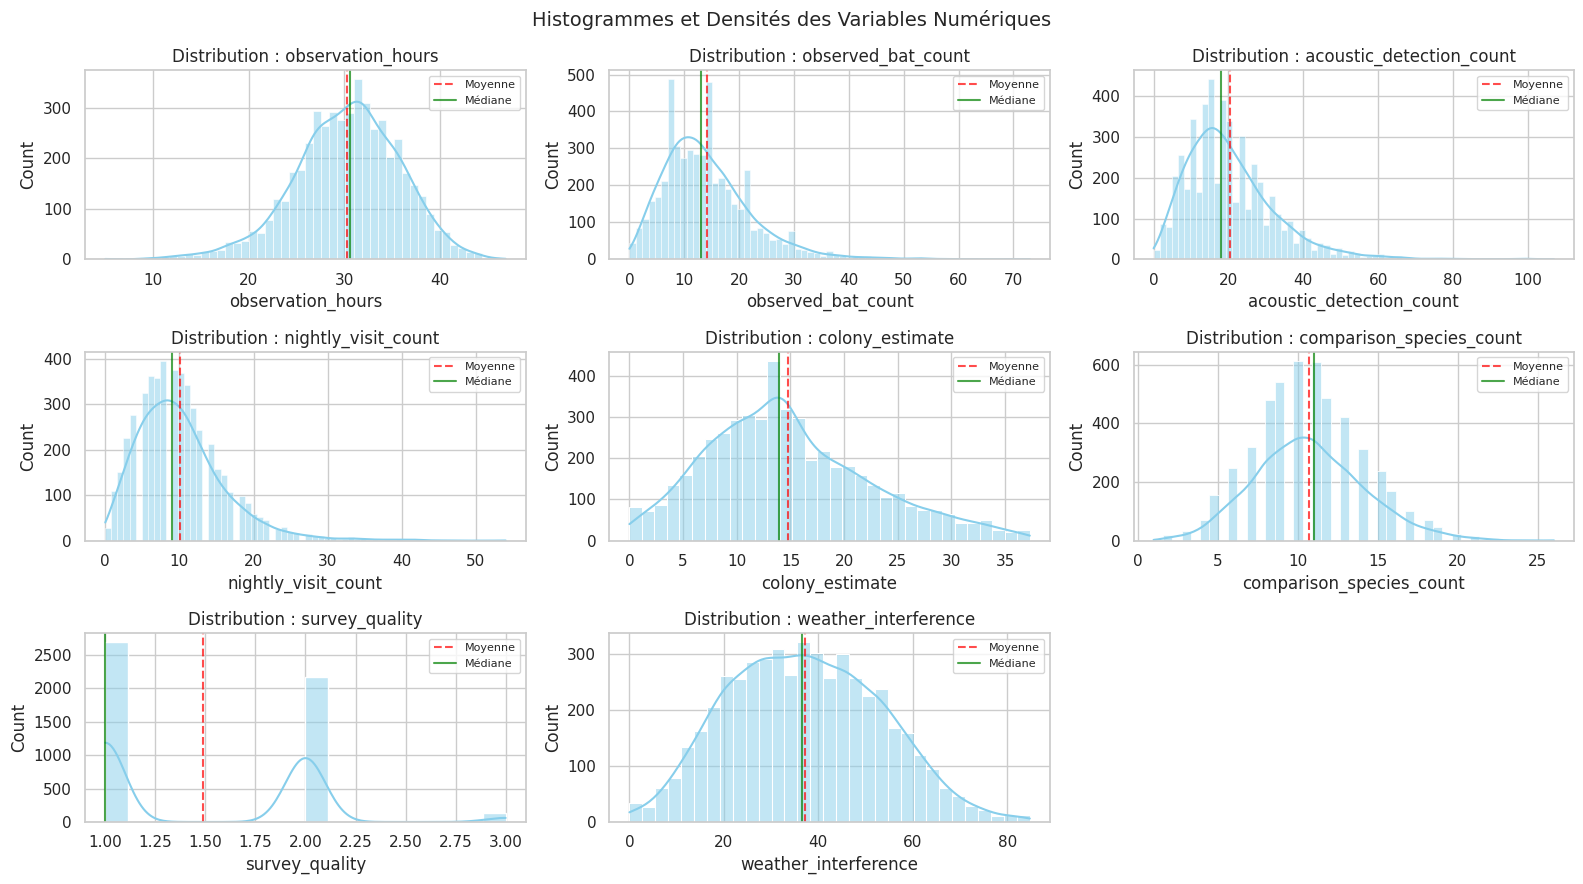

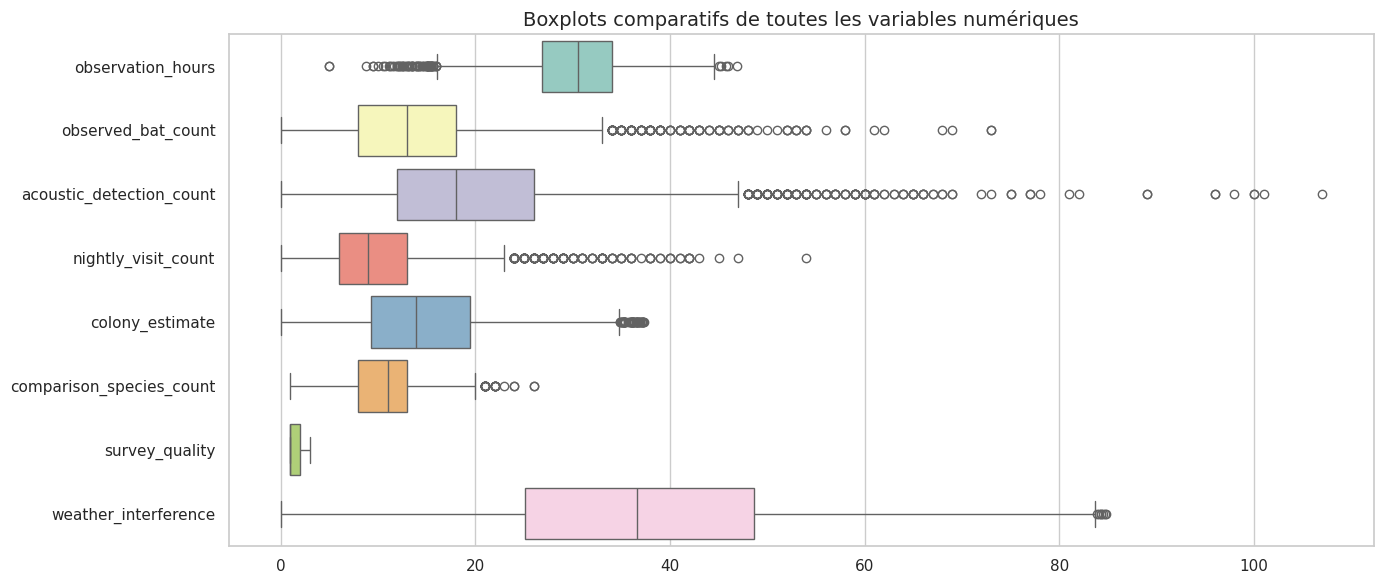

/tmp/ipykernel_20580/3911985157.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=order, palette="viridis", ax=axes[i])
/tmp/ipykernel_20580/3911985157.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=order, palette="viridis", ax=axes[i])
/tmp/ipykernel_20580/3911985157.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=order, palette="viridis", ax=axes[i])


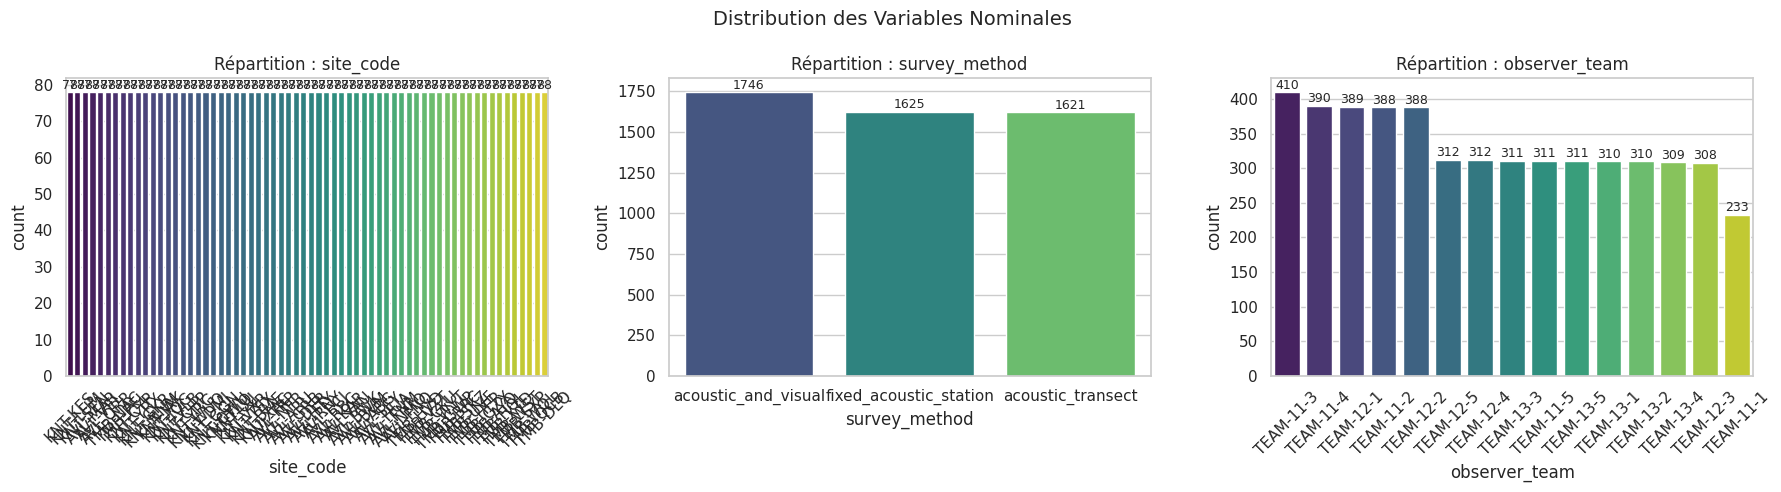

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. STATISTIQUES DES VARIABLES NUMÉRIQUES
# ==============================================================================
num_cols = df.select_dtypes(include=[np.number]).columns
stats_df = pd.DataFrame(
    {
        "Moyenne": df[num_cols].mean(),
        "Écart-type": df[num_cols].std(),
        "Min": df[num_cols].min(),
        "Q1 (25%)": df[num_cols].quantile(0.25),
        "Médiane": df[num_cols].median(),
        "Q3 (75%)": df[num_cols].quantile(0.75),
        "Max": df[num_cols].max(),
    }
)
print("=" * 60)
print("STATISTIQUES COMPLÈTES DES VARIABLES NUMÉRIQUES")
print("=" * 60)
print(stats_df.round(2))

# ==============================================================================
# 2. VISUALISATION 1 : TOUS LES HISTOGRAMMES EN UNE SEULE GRILLE
# ==============================================================================
n_num = len(num_cols)
fig, axes = plt.subplots(
    nrows=(n_num + 2) // 3, ncols=3, figsize=(16, 3 * ((n_num + 2) // 3))
)
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Distribution : {col}")
    axes[i].axvline(
        df[col].mean(), color="red", linestyle="--", alpha=0.7, label="Moyenne"
    )
    axes[i].axvline(
        df[col].median(),
        color="green",
        linestyle="-",
        alpha=0.7,
        label="Médiane",
    )
    axes[i].legend(fontsize=8)

# Masquer les sous-graphiques vides s'il y en a
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Histogrammes et Densités des Variables Numériques", fontsize=14)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. VISUALISATION 2 : TOUS LES BOXPLOTS COMPARÉS (PRIX / DISPERSION)
# ==============================================================================
plt.figure(figsize=(14, 6))
# Normalisation visuelle pour comparer toutes les colonnes numériques ensemble
sns.boxplot(data=df[num_cols], palette="Set3", orient="h")
plt.title(
    "Boxplots comparatifs de toutes les variables numériques", fontsize=14
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. VISUALISATION 3 : TOUTES LES VARIABLES NOMINALES EN UNE GRILLE
# ==============================================================================
cat_cols = df.select_dtypes(include=["object"]).columns
n_cat = len(cat_cols)

if n_cat > 0:
    fig, axes = plt.subplots(
        nrows=1, ncols=n_cat, figsize=(6 * n_cat, 5), squeeze=False
    )
    axes = axes.flatten()

    for i, col in enumerate(cat_cols):
        order = df[col].value_counts().index
        ax = sns.countplot(data=df, x=col, order=order, palette="viridis", ax=axes[i])
        axes[i].set_title(f"Répartition : {col}")
        axes[i].tick_params(axis="x", rotation=45 if df[col].nunique() > 5 else 0)

        # Effectifs sur les barres
        for p in ax.patches:
            height = int(p.get_height()) if not np.isnan(p.get_height()) else 0
            ax.annotate(
                f"{height}",
                (p.get_x() + p.get_width() / 2.0, p.get_height()),
                ha="center",
                va="center",
                xytext=(0, 5),
                textcoords="offset points",
                fontsize=9,
            )

    plt.suptitle("Distribution des Variables Nominales", fontsize=14)
    plt.tight_layout()
    plt.show()

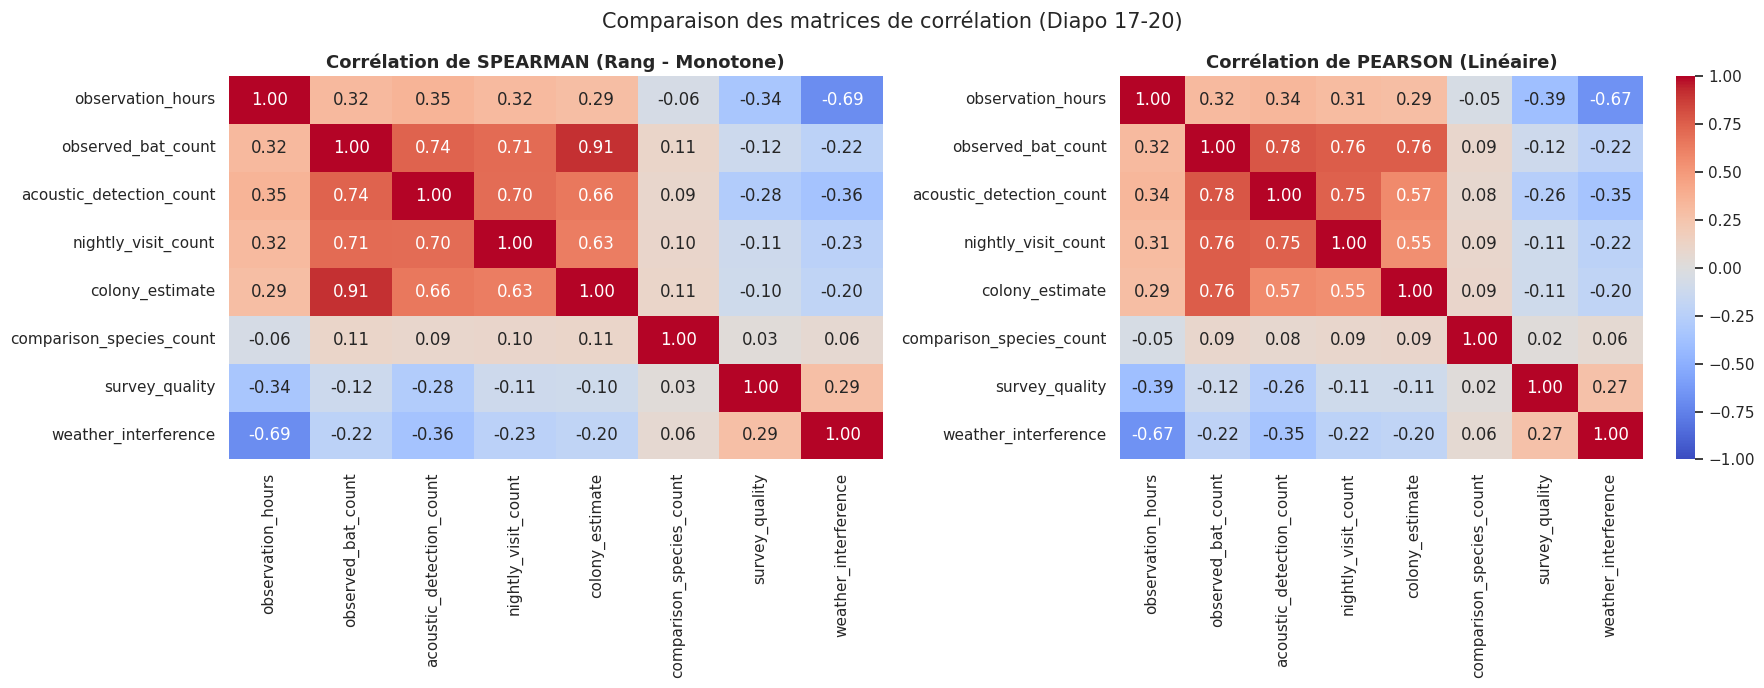

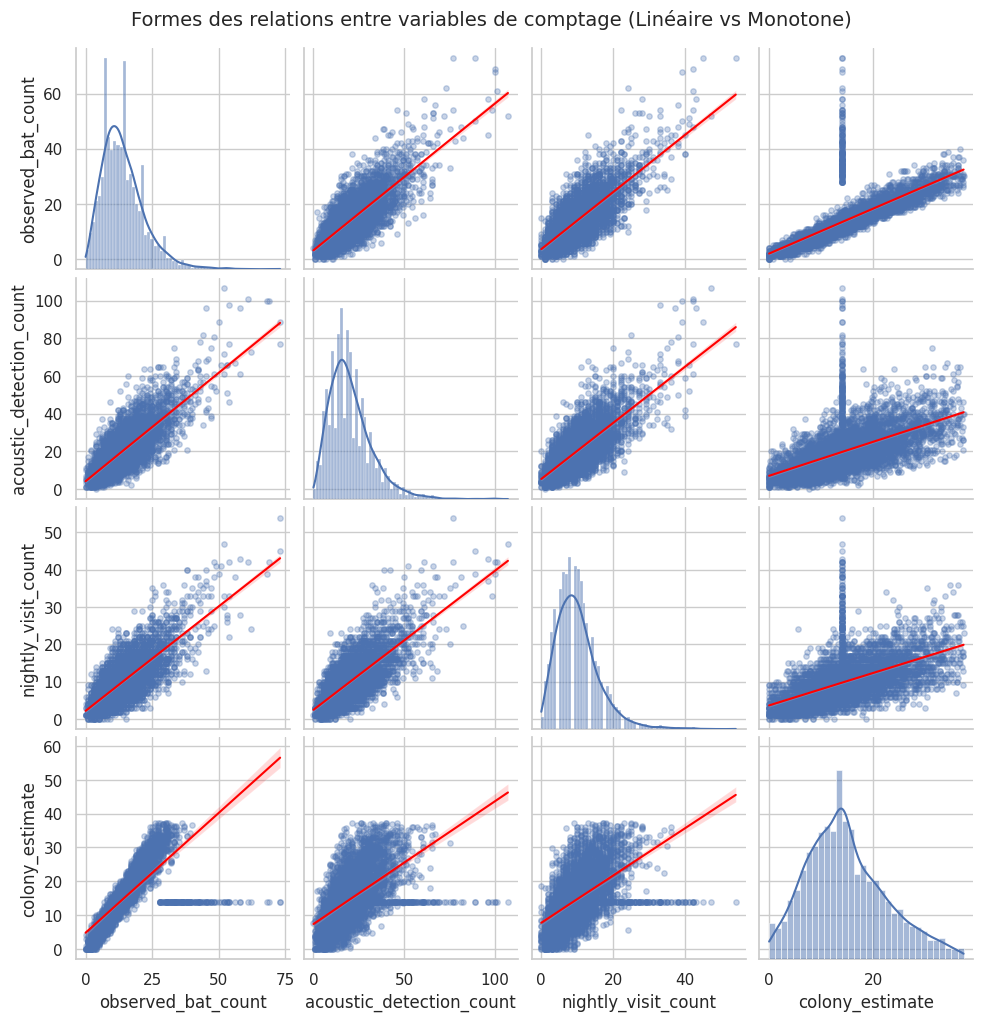

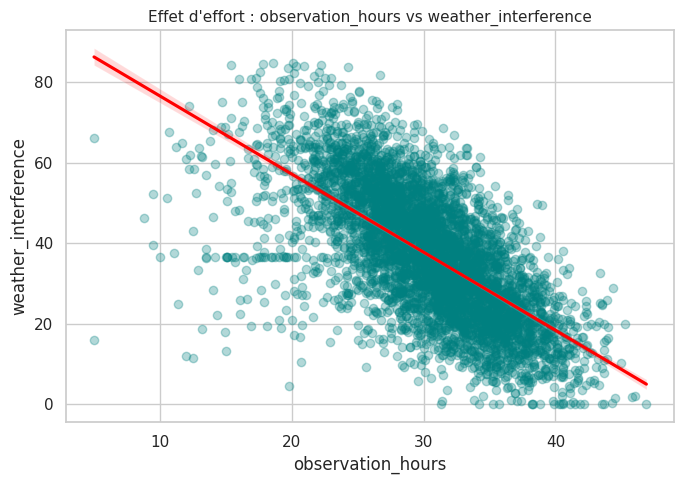

In [49]:
sns.set_theme(style="whitegrid")
num_cols = df.select_dtypes(include=[np.number]).columns

# ==============================================================================
# 1. MATRICES DE CORRÉLATION (SPEARMAN VS PEARSON) - TOUTES LES VARIABLES
# ==============================================================================
corr_spearman = df[num_cols].corr(method="spearman")
corr_pearson = df[num_cols].corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Matrice de Spearman (Prioritaire selon le cours)
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
    cbar=False,
)
axes[0].set_title(
    "Corrélation de SPEARMAN (Rang - Monotone)", fontsize=13, fontweight="bold"
)

# Matrice de Pearson
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title(
    "Corrélation de PEARSON (Linéaire)", fontsize=13, fontweight="bold"
)

plt.suptitle(
    "Comparaison des matrices de corrélation (Diapo 17-20)", fontsize=15
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 2. VISUALISATION DES PAIRPLOTS ET RELATIONS ENTRE VARIABLES CORRÉLÉES
# ==============================================================================
key_vars = [
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count",
    "colony_estimate",
]

g = sns.pairplot(
    df[key_vars],
    kind="reg",
    plot_kws={
        "line_kws": {"color": "red", "linewidth": 1.5},
        "scatter_kws": {"alpha": 0.3, "s": 15},
    },
    diag_kws={"kde": True},
)
g.fig.suptitle(
    "Formes des relations entre variables de comptage (Linéaire vs Monotone)",
    y=1.02,
    fontsize=14,
)
plt.show()

# ==============================================================================
# 3. RELATIONS SPÉCIFIQUES : HEURES D'OBSERVATION ET MÉTÉO VS COMPTAGES
# ==============================================================================
fig, ax = plt.subplots(figsize=(7, 5))

# Impact des heures d'observation sur le comptage (Effet d'effort)
sns.regplot(
    data=df,
    x="observation_hours",
    y="weather_interference",
    ax=ax,
    color="teal",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"},
)
ax.set_title(
    "Effet d'effort : observation_hours vs weather_interference", fontsize=11
)

plt.tight_layout()
plt.show()